# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Федів Андрій Сергійович'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 13      # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 13, файл lr6_варіант_13.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 67
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
# ----- ВАШІ ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'      # 'класифікація' / 'регресія' / 'кластеризація' / 'зменшення розмірності'
# чому: ціль має два класи — пішов або лишився  #

METRIC = 'AUC'            # 'точність' / 'AUC' / 'F1' / 'повнота' / 'MAE'
# чому саме ця, а не точність: відтік лише 27 %, тож «ніхто не піде» вже дає точність 73 %, а AUC від порога не залежить  #

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'         # напр. 'стратифікована 5-кратна, 4 повтори'
# чому саме така: у кожній згортці та сама частка відтоку, а 20 навчань дають розкид  #

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.266

типи стовпців: {'object': 13, 'float64': 7, 'int64': 6}


In [6]:
info = pd.DataFrame({'тип': raw.dtypes, 'унікальних': raw.nunique(),  #
                     '% пропусків': raw.isna().mean() * 100, 'приклад': raw.iloc[0]})  #
info.sort_values('% пропусків', ascending=False)  #

,тип,унікальних,% пропусків,приклад
код_причини_закриття,object,5,73.416667,NaN
сума_повернення_депозиту,float64,317,73.416667,NaN
середній_час_відповіді_хв,float64,273,33.166667,14.4
трафік_ГБ,object,966,5.000000,82.5
щомісячний_платіж,object,1128,4.000000,329.8
аварій_на_ділянці_за_квартал,float64,5,3.000000,0.0
стать,object,6,0.000000,чол
місто,object,6,0.000000,Львів
id_клієнта,object,1200,0.000000,K130000
вік,float64,64,0.000000,51.0


**Висновок до завдання 2.1:**

1200 рядків і 26 стовпців. Відтік 26,6 %. 13 стовпців мають тип object. Найбільше пропусків у код_причини_закриття і сума_повернення_депозиту (73,4 %).

### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
# text in numeric
s = raw['щомісячний_платіж'].dropna()  #
print(s[pd.to_numeric(s, errors='coerce').isna()].head(3))  #
# excel dates
print(raw['трафік_ГБ'][raw['трафік_ГБ'].str.startswith('1900', na=False)])  #
# mnar: missing time = no calls
raw.groupby(raw['середній_час_відповіді_хв'].isna())[[TARGET, 'кількість_звернень_у_підтримку']].mean()  #

22     304.14 грн
74     428.94 грн
208     306.1 грн
Name: щомісячний_платіж, dtype: object
73      1900-01-18 00:00:00
259     1900-01-08 00:00:00
1001    1900-01-22 00:00:00
Name: трафік_ГБ, dtype: object


,відтік,кількість_звернень_у_підтримку
середній_час_відповіді_хв,,
False,0.300499,1.699501
True,0.195980,0.000000


In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'    # назва стовпця  #
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'    # назва стовпця  #
PROBLEM_MNAR           = 'середній_час_відповіді_хв'    # назва стовпця  #
MNAR_MEANING           = 'клієнт не звертався в підтримку, тому часу відповіді немає; такі йдуть рідше (19,6 % проти 30,0 %)'  #

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


**Висновок до завдання 2.2:**

У щомісячний_платіж 25 значень записано з «грн». У трафік_ГБ 3 числа стали датами 1900 року. Пропуск у середній_час_відповіді_хв означає, що клієнт не звертався в підтримку.

---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        # dates -> nan
        if isinstance(v, datetime.date):  #
            return np.nan  #
        try:  #
            return float(str(v).replace('грн', '').replace(',', '.'))  #
        except ValueError:  # words, dates as text  #
            return np.nan  #
    return s.map(one)


# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [10]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується
# fix sex spelling: ч/Ч/чол -> ч, ж/Ж/жін -> ж
raw['стать'] = raw['стать'].str.lower().str[0]  #

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        s = d[c]  #
        if s.dtype != object:  #
            X[c] = s.astype(float)  #
        # mostly numbers in text
        elif to_number(s).notna().mean() > 0.8:  #
            X[c] = to_number(s)  #
        # mostly dates -> day number
        elif pd.to_datetime(s, errors='coerce').notna().mean() > 0.8:  #
            X[c] = (pd.to_datetime(s) - pd.Timestamp('1970-01-01')).dt.days  #
        else:  #
            X[c] = s.str.strip().str.lower().astype('category')  #
        log.append((c, str(X[c].dtype)))  #
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 9


,0,1
0,вік,float64
1,стать,category
2,місто,category
3,філія,category
4,тариф,category
5,тип_підключення,category
6,спосіб_оплати,category
7,автоплатіж,category
8,кількість_послуг,float64
9,місяців_обслуговування,float64


**Висновок до завдання 3.1:**

Вийшло 24 ознаки: 15 числових і 9 категоріальних. Дата підключення стала номером дня, стать зведено до двох значень.

### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X, clf):
    cat = [c for c in X.columns if str(X[c].dtype) == 'category']  #
    num = [c for c in X.columns if c not in cat]  #
    prep = ColumnTransformer([  #
        ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')),  #
                          ('scaler', StandardScaler())]), num),  #
        ('category', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),  #
                          ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat),  #
    ], sparse_threshold=0)  #
    return Pipeline([('prep', prep), ('clf', clf)])  #


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.990


**Висновок до завдання 3.2:**

Уся обробка сидить усередині конвеєра. Пробний прогін дав AUC 0,990, це підозріло високо.

---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.987 ± 0.007
час      : 0.6 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = 'AUC 0,987 занадто висока для реальних даних, тож найімовірніше це витік: у таблиці є стовпці, записані вже після відтоку.'  #
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

AUC 0,987 занадто висока для реальних даних, тож найімовірніше це витік: у таблиці є стовпці, записані вже після відтоку.


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        f = d[c].notna()  #
        # skip tiny groups
        if min(f.sum(), (~f).sum()) < min_group:  #
            continue  #
        a = roc_auc_score(y, f)  #
        rows.append({'ознака': c, 'заповнено': f.sum(), 'частка_відтоку_де_заповнено': y[f].mean(),  #
                     'частка_відтоку_де_пропуск': y[~f].mean(), 'показник': max(a, 1 - a)})  #
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
4,сума_повернення_депозиту,319,1.000000,0.000000,1.000000
5,код_причини_закриття,319,1.000000,0.000000,1.000000
3,середній_час_відповіді_хв,802,0.300499,0.195980,0.559355
0,щомісячний_платіж,1152,0.269097,0.187500,0.508027
1,трафік_ГБ,1140,0.263158,0.316667,0.506512
2,аварій_на_ділянці_за_квартал,1164,0.268041,0.194444,0.505487


**Висновок до завдання 5.1:**

Показник 1,0 мають сума_повернення_депозиту і код_причини_закриття: вони заповнені лише в тих, хто пішов.

### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = [
    'сума_повернення_депозиту',   # депозит повертають, коли договір уже розірвано  #
    'код_причини_закриття',       # причину пишуть у момент розірвання  #
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['сума_повернення_депозиту', 'код_причини_закриття']


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.922 ± 0.017


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'річний_платіж', 'код_тарифного_плану', 'скоринг_партнера', 'дата_підключення', 'кількість_дзвінків_утримання']


In [18]:
HUMAN_LEAK = [
    'кількість_дзвінків_утримання',
]
HUMAN_LEAK_WHY = 'детектор дивиться лише на заповненість, а це поле заповнене в усіх клієнтів; витік сидить у самих значеннях.'  #

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.860 ± 0.024


**Висновок до завдання 5.3:**

Без дзвінків утримання AUC упала з 0,922 до 0,860.

> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

In [19]:
# churn by branch
display(raw.groupby('філія')[TARGET].agg(['mean', 'size']))  #
# churn by quarter
raw.groupby(pd.to_datetime(raw['дата_підключення']).dt.to_period('Q'))[TARGET].mean()  #

,mean,size
філія,,
Ф-01 Центр,0.400000,215
Ф-02 Захід,0.439024,205
Ф-03 Схід,0.177419,186
Ф-04 Південь,0.190217,184
Ф-05 Північ,0.179104,201
Ф-06 Приміська,0.186603,209


дата_підключення
2023Q1    0.302632
2023Q2    0.272152
2023Q3    0.219858
2023Q4    0.300699
2024Q1    0.304965
2024Q2    0.256410
2024Q3    0.224242
2024Q4    0.250000
Freq: Q-DEC, Name: відтік, dtype: float64

**Висновок до завдання 6.1:**

У Ф-01 і Ф-02 відтік 0,40 і 0,44, в інших філіях близько 0,18. За кварталами сходинки немає.

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT = 'філія'  #
assert SUSPECT in ('філія', 'дата_підключення')

source = raw['філія'].isin(['Ф-01 Центр', 'Ф-02 Захід']).astype(int)  #

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.676
ті самі ознаки передбачають ВІДТІК  : AUC 0.824 ± 0.029


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.987
2. мінус цільовий витік,22,0.922
3. мінус оцінки людини,21,0.860
4. мінус артефакт збору,20,0.824


чесне число: 0.824 ± 0.029


**Висновок до завдання 6.3:**

AUC падала так: 0,987 → 0,922 → 0,860 → 0,824. Чесне число — 0,824 ± 0,029.

### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
DECISION_ARTEFACT = 'викинути'  #
DECISION_WHY = 'у Ф-01 і Ф-02 відтік стрибком удвічі вищий, це схоже на інше правило обліку, а модель має працювати в будь-якій філії.'  #
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

викинути — у Ф-01 і Ф-02 відтік стрибком удвічі вищий, це схоже на інше правило обліку, а модель має працювати в будь-якій філії.


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [23]:
from sklearn.tree import DecisionTreeClassifier  #

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(random_state=SEED),  #
    'випадковий ліс':       RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),  #
    'gbdt': HistGradientBoostingClassifier(random_state=SEED),  #
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.824,0.029,0.6
одне дерево,0.656,0.036,0.4
випадковий ліс,0.830,0.027,12.5
gbdt,0.833,0.030,13.3


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [24]:
def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    d = np.asarray(b) - np.asarray(a)  #
    return d.mean(), 2 * d.std() / np.sqrt(len(d))  #


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'gbdt']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: +0.0059 ± 0.0110   у межах шуму


gbdt                   проти логістичної: +0.0097 ± 0.0098   у межах шуму


**Висновок до завдання 7.2:**

Ліс і бустинг кращі лише на 0,006 і 0,010, це в межах шуму. Одне дерево найгірше (0,656).

In [25]:
CHOSEN_MODEL = 'логістична регресія'  #
CHOSEN_WHY = 'ліс і бустинг кращі лише в межах шуму, а логістична регресія у десятки разів швидша і простіше пояснюється.'  #
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: логістична регресія — ліс і бустинг кращі лише в межах шуму, а логістична регресія у десятки разів швидша і простіше пояснюється.


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [26]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    # часті звернення за короткий стаж — клієнт незадоволений
    F['звернень_на_місяць'] = F['кількість_звернень_у_підтримку'] / (F['місяців_обслуговування'] + 1)  #
    # мало трафіку за гривню — клієнт переплачує
    F['трафік_на_гривню'] = F['трафік_ГБ'] / F['щомісячний_платіж']  #
    # новачок прийшов за знижкою і піде, коли вона набридне
    F['новий_зі_знижкою'] = ((F['місяців_обслуговування'] <= 24) & (F['знижка_відсоток'] > 0)).astype(float)  #
    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 23


In [27]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.836 ± 0.029
приріст проти базового набору: +0.0126 ± 0.0034   значуще


**Висновок до завдання 8.1:**

Нові ознаки підняли AUC з 0,824 до 0,836, приріст значущий.

### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [28]:
FEATURES_VS_MODEL = 'Нові ознаки дали більше: +0,0126 ± 0,0034 майже без додаткового часу, а ліс і бустинг лише +0,0059 ± 0,0110 і +0,0097 ± 0,0098 у межах шуму і в десятки разів довше.'  #
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

Нові ознаки дали більше: +0,0126 ± 0,0034 майже без додаткового часу, а ліс і бустинг лише +0,0059 ± 0,0110 і +0,0097 ± 0,0098 у межах шуму і в десятки разів довше.


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [29]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.809
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

<Axes: >

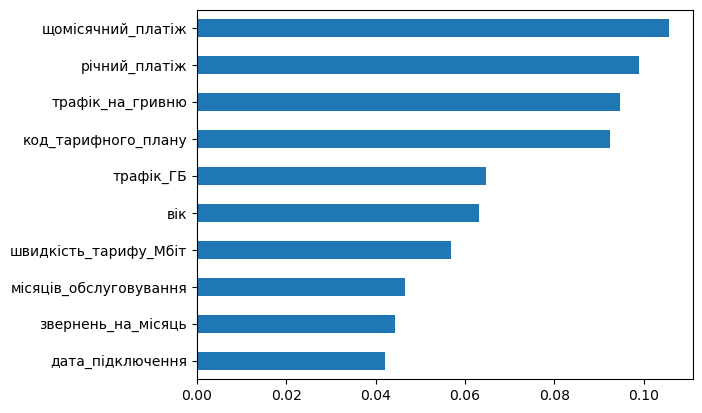

In [30]:
# sum dummy columns per feature
names = model.named_steps['prep'].get_feature_names_out()  #
imp = model.named_steps['clf'].feature_importances_  #
gini_imp = pd.Series({c: imp[[n == 'numeric__' + c or n.startswith('category__' + c + '_') for n in names]].sum()  #
                      for c in FINAL_X.columns}).sort_values()  #
gini_imp.tail(10).plot.barh()  #

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [31]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp)

трафік_на_гривню                  0.025673
вік                               0.021254
звернень_на_місяць                0.015019
річний_платіж                     0.013988
місяців_обслуговування            0.012989
аварій_на_ділянці_за_квартал      0.012883
кількість_звернень_у_підтримку    0.012863
швидкість_тарифу_Мбіт             0.010109
автоплатіж                        0.010014
щомісячний_платіж                 0.008795
трафік_ГБ                         0.008110
новий_зі_знижкою                  0.004204
дата_підключення                  0.002967
тариф                             0.002545
знижка_відсоток                   0.002304
тип_підключення                   0.001635
кількість_послуг                  0.001361
скоринг_партнера                  0.000039
місто                            -0.000400
спосіб_оплати                    -0.000619
стать                            -0.000659
середній_час_відповіді_хв        -0.001584
код_тарифного_плану              -0.005842
dtype: floa

### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [32]:
pd.DataFrame({'вбудована': gini_imp, 'перестановочна': perm_imp}).sort_values('вбудована', ascending=False)  #

,вбудована,перестановочна
щомісячний_платіж,0.105705,0.008795
річний_платіж,0.098865,0.013988
трафік_на_гривню,0.094597,0.025673
код_тарифного_плану,0.092388,-0.005842
трафік_ГБ,0.064693,0.008110
вік,0.063149,0.021254
швидкість_тарифу_Мбіт,0.056807,0.010109
місяців_обслуговування,0.046468,0.012989
звернень_на_місяць,0.044275,0.015019
дата_підключення,0.042085,0.002967


In [33]:
FAKE_IMPORTANT = 'код_тарифного_плану'  #
FAKE_IMPORTANT_WHY = '40 рівнів дають дереву багато можливих розбиттів, і якесь із них випадково зменшує неоднорідність на навчальних даних, хоча зв’язку з відтоком немає.'  #
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

хибно важлива ознака: код_тарифного_плану


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [34]:
corr = FINAL_X.select_dtypes('number').corr().abs().stack()  #
corr[corr < 1].sort_values(ascending=False).head(8)  #

щомісячний_платіж      річний_платіж            0.999276
річний_платіж          щомісячний_платіж        0.999276
трафік_на_гривню       трафік_ГБ                0.886079
трафік_ГБ              трафік_на_гривню         0.886079
швидкість_тарифу_Мбіт  щомісячний_платіж        0.742601
щомісячний_платіж      швидкість_тарифу_Мбіт    0.742601
швидкість_тарифу_Мбіт  річний_платіж            0.741924
річний_платіж          швидкість_тарифу_Мбіт    0.741924
dtype: float64

In [35]:
DUP_PAIR = ['щомісячний_платіж', 'річний_платіж']  #
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

# retrain without the pair
X_one = FINAL_X.drop(columns=DUP_PAIR[1])  #
m_one = make_pipe(X_one, RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)).fit(Xtr[X_one.columns], ytr)  #
p_one = permutation_importance(m_one, Xte[X_one.columns], yte, n_repeats=10, random_state=SEED, scoring='roc_auc')  #
print(p_one.importances_mean[list(X_one.columns).index(DUP_PAIR[0])])  #

у повній моделі:
   щомісячний_платіж            +0.0088
   річний_платіж                +0.0140


0.03611702967171713


In [36]:
DUP_EXPLANATION = 'Платежі дублюють один одного, тому при перемішуванні одного модель бере ціну з другого і важливість ділиться між ними; без річного важливість щомісячного зросла з 0,0088 до 0,0361. Метод не бреше: він показує, наскільки гірше без однієї колонки, коли друга лишилась.'  #
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

Платежі дублюють один одного, тому при перемішуванні одного модель бере ціну з другого і важливість ділиться між ними; без річного важливість щомісячного зросла з 0,0088 до 0,0361. Метод не бреше: він показує, наскільки гірше без однієї колонки, коли друга лишилась.


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

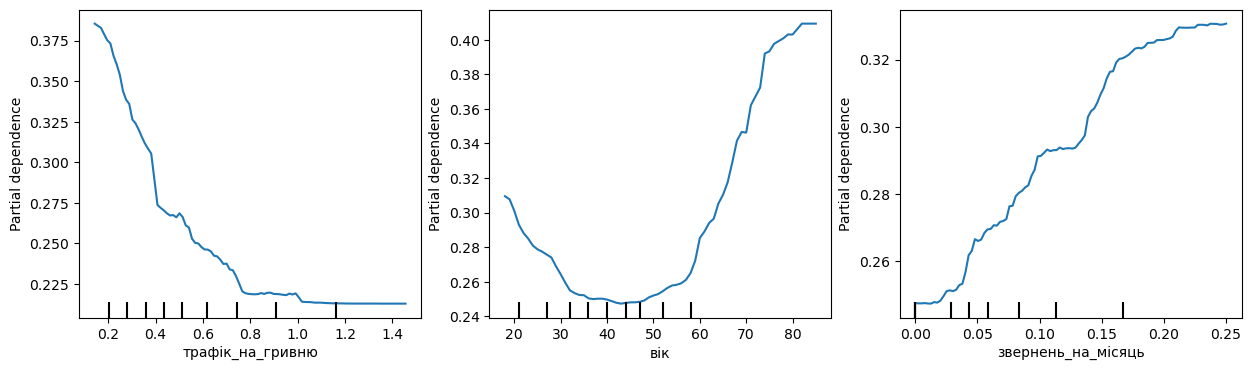

In [37]:
from sklearn.inspection import PartialDependenceDisplay

# top-3 numeric by permutation, rows without nan
fig, axes = plt.subplots(1, 3, figsize=(15, 4))  #
for c, ax in zip(['трафік_на_гривню', 'вік', 'звернень_на_місяць'], axes):  #
    PartialDependenceDisplay.from_estimator(model, FINAL_X[FINAL_X[c].notna()], [c], ax=ax)  #

**Висновок до завдання 10.1:**

Що менше трафіку на гривню, то вищий ризик. За віком крива має яму біля 42 років. Що частіше клієнт звертається в підтримку, то вищий ризик: від 0,25 до 0,33.

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

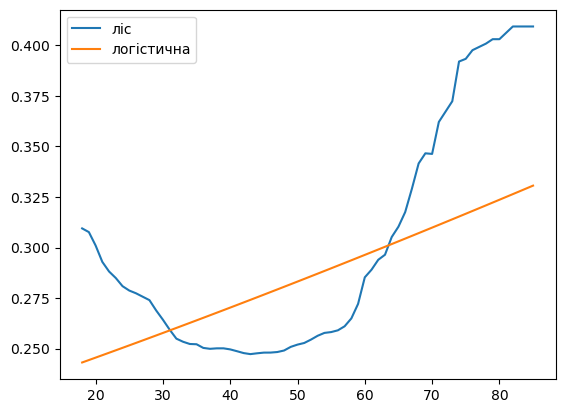

In [38]:
NONLINEAR_FEATURE = 'вік'  #
assert NONLINEAR_FEATURE in FINAL_X.columns

# forest vs logreg
lr_model = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)  #
for m in [model, lr_model]:  #
    r = partial_dependence(m, FINAL_X, ['вік'])  #
    plt.plot(r['grid_values'][0], r['average'][0])  #
plt.legend(['ліс', 'логістична'])  #

In [39]:
NONLINEAR_MEANING = 'ризик високий у молодих, найнижчий біля 42 років і знову росте в старших.'  #
NONLINEAR_FIX = 'додати ознаку (вік − 42)²'  #
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

ризик високий у молодих, найнижчий біля 42 років і знову росте в старших.
додати ознаку (вік − 42)²


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [40]:
# 42 = min risk on pdp
X_q = FINAL_X.assign(вік_2=(FINAL_X['вік'] - 42) ** 2)  #
auc_q = cross_val_score(make_pipe(X_q, logreg()), X_q, y, cv=cv, scoring='roc_auc')  #
m_q, h_q = paired(auc5, auc_q)  #
print(auc5.mean(), auc_q.mean(), m_q, h_q)  #

0.8363350204336035 0.8688239334425776 0.032488913008973906 0.0052528661711510145


**Висновок до завдання 10.2б:**

Ознака (вік − 42)² підняла AUC логістичної регресії з 0,836 до 0,869.

In [41]:
QUAD_GAIN = m_q  #
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0325


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

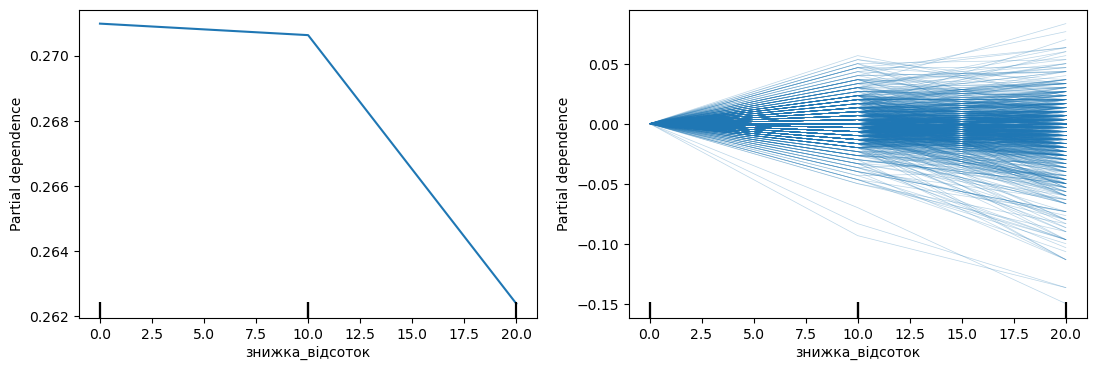

In [42]:
# plain pdp (left), ice for every client (right)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))  #
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='average', ax=axes[0])  #
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='individual', centered=True, ax=axes[1])  #

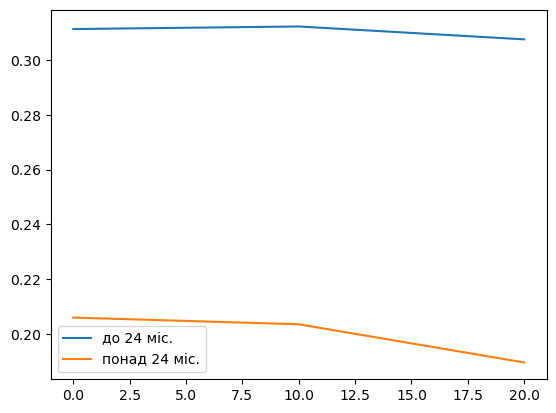

In [43]:
young = FINAL_X['місяців_обслуговування'] <= 24  #
for mask in [young, ~young]:  #
    r = partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'])  #
    plt.plot(r['grid_values'][0], r['average'][0])  #
plt.legend(['до 24 міс.', 'понад 24 міс.'])  #

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [44]:
# raw churn by tenure and discount
raw.groupby([raw['місяців_обслуговування'] > 24, 'знижка_відсоток'])[TARGET].agg(['mean', 'size'])  #

mean  size
місяців_обслуговування знижка_відсоток                
False                  0                0.259649   285
                       10               0.362637   273
                       20               0.366120   183
True                   0                0.245989   187
                       10               0.198630   146
                       20               0.031746   126

**Висновок до завдання 10.3:**

PDP по всій вибірці майже пласкі, а ICE розходяться в різні боки. Сирі дані це підтверджують: знижка утримує старих клієнтів, але не новачків.

In [45]:
INTERACTION_FOUND = 'у клієнтів зі стажем понад 24 міс. знижка зменшує відтік (24,6 % → 3,2 %), а в новачків відтік зі знижкою вищий (26,0 % → 36,6 %).'  #
BUSINESS_ACTION = 'знижку для утримання пропонувати клієнтам зі стажем понад 2 роки, новачкам вона не допомагає.'  #
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

у клієнтів зі стажем понад 24 міс. знижка зменшує відтік (24,6 % → 3,2 %), а в новачків відтік зі знижкою вищий (26,0 % → 36,6 %).
знижку для утримання пропонувати клієнтам зі стажем понад 2 роки, новачкам вона не допомагає.


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [46]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 76)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

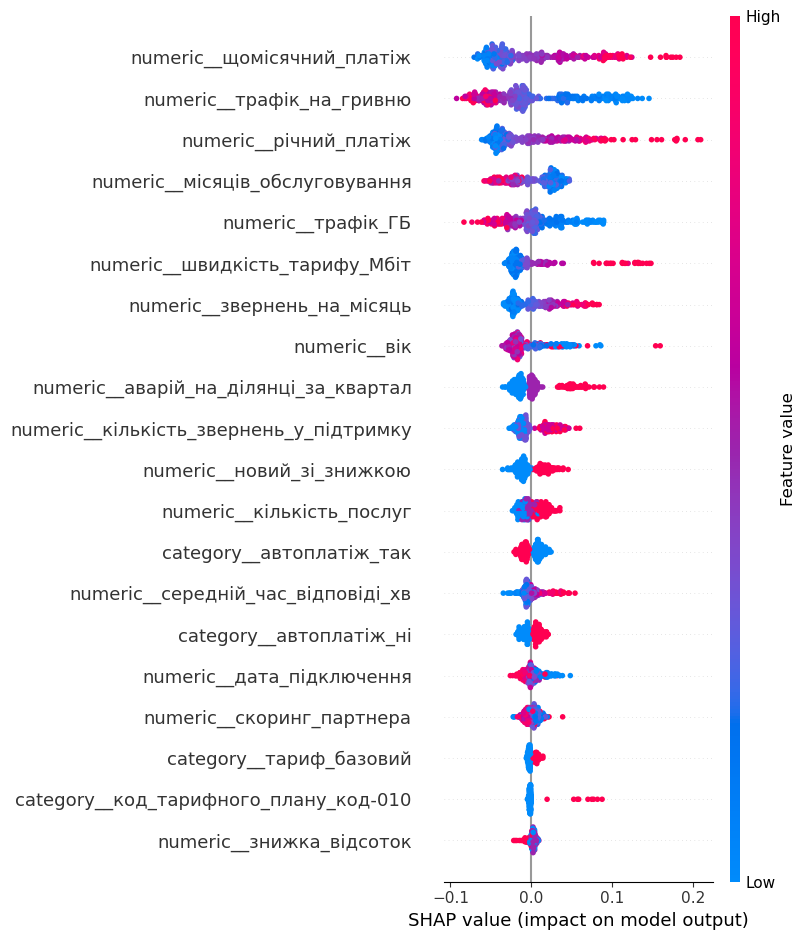

In [47]:
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names)  #

**Висновок до завдання 11.2:**

Дорогий тариф і малий трафік підвищують ризик, великий стаж знижує. Напрям не однаковий для всіх: за віком ризик підвищують і молоді, і літні клієнти.

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [48]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

# top-3 contributions
display(pd.Series(sv1[idx], index=feat_names).sort_values(key=abs).tail(3))  #
Xte.iloc[idx]  #

ризик клієнта: 0.877


numeric__швидкість_тарифу_Мбіт    0.130992
numeric__щомісячний_платіж        0.183491
numeric__річний_платіж            0.190139
dtype: float64

вік                                      34.0
стать                                       ч
місто                                   львів
тариф                             оптимальний
тип_підключення                        оптика
спосіб_оплати                          картка
автоплатіж                                 ні
кількість_послуг                          1.0
місяців_обслуговування                   48.0
швидкість_тарифу_Мбіт                  1000.0
щомісячний_платіж                       595.6
знижка_відсоток                          10.0
трафік_ГБ                               124.7
кількість_звернень_у_підтримку            3.0
аварій_на_ділянці_за_квартал              0.0
середній_час_відповіді_хв                12.9
річний_платіж                          7224.7
код_тарифного_плану                   код-024
скоринг_партнера                      248.109
дата_підключення                        19577
звернень_на_місяць                   0.061224
трафік_на_гривню                  

In [49]:
EXPLANATION_FOR_MANAGER = 'Клієнт, найімовірніше, піде (ризик близько 90 %). Головна причина — висока ціна: 596 грн на місяць за найшвидший тариф 1000 Мбіт. Варто запропонувати дешевший тариф.'  #
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Клієнт, найімовірніше, піде (ризик близько 90 %). Головна причина — висока ціна: 596 грн на місяць за найшвидший тариф 1000 Мбіт. Варто запропонувати дешевший тариф.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [50]:
SHAP_NOT_CAUSAL_FEATURE = 'місяців_обслуговування'  #
SHAP_NOT_CAUSAL_WHY = 'великий стаж сильно знижує ризик, але стаж не можна змінити: клієнтові не додаси років обслуговування, тож ця ознака лише показує, кого не варто обдзвонювати.'  #
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

місяців_обслуговування — великий стаж сильно знижує ризик, але стаж не можна змінити: клієнтові не додаси років обслуговування, тож ця ознака лише показує, кого не варто обдзвонювати.


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [51]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",код_тарифного_плану,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",щомісячний_платіж + річний_платіж,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",місяців_обслуговування,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [52]:
FIFTH_MISTAKE = 'середній_час_відповіді_хв: у 398 клієнтів без звернень пропуск заповнено медіаною, тож пояснення моделі говорять про час відповіді, якого насправді не було.'  #
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

середній_час_відповіді_хв: у 398 клієнтів без звернень пропуск заповнено медіаною, тож пояснення моделі говорять про час відповіді, якого насправді не було.


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [53]:
TOP_N = 100
risk = model.predict_proba(Xte)[:, 1]  #
# churners among top-100 by risk
top = yte.values[np.argsort(-risk)[:TOP_N]]  #
lift = top.mean() / yte.mean()  #
print(top.sum(), lift)  #

57 2.1374999999999997


**Висновок до завдання 13.1:**

У топ-100 пішли 57 клієнтів, навмання було б 27. Lift 2,14.

In [54]:
LIFT_MEANING = 'серед 100 найризикованіших 57 справді пішли, навмання було б близько 27, тобто дзвінки в 2,1 раза результативніші'  #
assert LIFT_MEANING
print(LIFT_MEANING)

серед 100 найризикованіших 57 справді пішли, навмання було б близько 27, тобто дзвінки в 2,1 раза результативніші


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [55]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_13.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [56]:
REPORT = '''
1. AUC, бо вона не залежить від порога і дисбалансу класів. Модель «ніхто не піде» мала б точність 73,4 %.
2. id_клієнта — технічний номер; сума_повернення_депозиту і код_причини_закриття з'являються при розірванні;
   кількість_дзвінків_утримання — після того, як клієнт сказав, що йде; філія — артефакт збору, викинута, щоб модель працювала в будь-якій філії.
   Детектор не знайшов дзвінки утримання, бо вони заповнені в усіх клієнтів.
3. AUC 0,824 ± 0,029. Різниця 0,004 набагато менша за розкид, тож такі моделі без парного порівняння не розрізнити.
4. Так: у Ф-01 і Ф-02 відтік удвічі вищий, AUC передбачення джерела 0,676. В іншій філії модель треба перевіряти окремо.
5. Нові ознаки: +0,0126 ± 0,0034. Ліс: +0,0059 ± 0,0110, бустинг: +0,0097 ± 0,0098, обидва в межах шуму.
   На 20 навчань ліс і бустинг витрачають понад 10 с, логістична регресія менше 1 с. Більше дали ознаки.
6. код_тарифного_плану: 4-те місце за вбудованою (0,0924), перестановочна −0,0058. 40 рівнів дають багато можливих
   розбиттів, і якесь випадково виглядає корисним.
7. Важливість ділилась між щомісячним і річним платежем (0,0088 і 0,0140), без річного щомісячний отримав 0,0361.
   Метод правильно показує, що без однієї колонки модель майже нічого не втрачає, бо є друга.
8. Вік. Логістична регресія цього не бачить; з ознакою (вік − 42)² її AUC зросла з 0,836 до 0,869.
9. На знижці: PDP майже пласкі, а ICE показали, що в одних клієнтів знижка знижує ризик, в інших — ні.
10. місяців_обслуговування: модель активно ним користується (давні клієнти майже не йдуть), але стаж не змінити дзвінком.
    «Модель цим користується» — ознака допомагає вгадати, хто піде; «це причина» — зміна ознаки змінила б результат.
11. Lift 2,14: зі 100 обдзвонених 57 справді збиралися піти. Застереження: модель показує, хто піде, а не кого врятує дзвінок.

Декларація про використання ШІ:
використовував ChatGPT для синтаксису, функцій із бібліотек та допомоги в трактуванні окремих резцльтатів (Шеплі, влив філій, PDP/ICE)
'''
print(REPORT)


1. AUC, бо вона не залежить від порога і дисбалансу класів. Модель «ніхто не піде» мала б точність 73,4 %.
2. id_клієнта — технічний номер; сума_повернення_депозиту і код_причини_закриття з'являються при розірванні;
   кількість_дзвінків_утримання — після того, як клієнт сказав, що йде; філія — артефакт збору, викинута, щоб модель працювала в будь-якій філії.
   Детектор не знайшов дзвінки утримання, бо вони заповнені в усіх клієнтів.
3. AUC 0,824 ± 0,029. Різниця 0,004 набагато менша за розкид, тож такі моделі без парного порівняння не розрізнити.
4. Так: у Ф-01 і Ф-02 відтік удвічі вищий, AUC передбачення джерела 0,676. В іншій філії модель треба перевіряти окремо.
5. Нові ознаки: +0,0126 ± 0,0034. Ліс: +0,0059 ± 0,0110, бустинг: +0,0097 ± 0,0098, обидва в межах шуму.
   На 20 навчань ліс і бустинг витрачають понад 10 с, логістична регресія менше 1 с. Більше дали ознаки.
6. код_тарифного_плану: 4-те місце за вбудованою (0,0924), перестановочна −0,0058. 40 рівнів дають багато можливи

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.